<a href="https://colab.research.google.com/github/M1000Lord/zero-trust-vault/blob/master/Lab_2_for_cloud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intro to Cloud Computing (61773) – Lab 2: JSON in Colab
**Team Shablool** – Ali Armosh (ali.armosh@e.braude.ac.il), Omri Tafesh (omri.tafesh@e.braude.ac.il)

Part A runs every example from Tutorial 2 (JSON basics, the GeoIP examples, the Python↔JSON types, the concluding APOD example, updating a record, multiple records and web scraping).
Part B is the exercise: `students.json` on Drive, a Colab form with a student dropdown, details in text boxes, and an Update button that writes the student's favorite show back into the JSON file.

## 0. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive

Mounted at /content/drive
/content/drive/MyDrive


# Part A – Tutorial examples
## 1. The `json` module
`dump()` writes JSON to a file, `load()` reads JSON from a file, `dumps()` encodes to a JSON string and `loads()` decodes a JSON string.

In [2]:
import json

person = {'name': 'Ali', 'courses': ['Cloud', 'WEB'], 'student': True}

s = json.dumps(person)                 # dumps: Python -> JSON string
print('dumps :', s, type(s))
print('loads :', json.loads(s), type(json.loads(s)))   # loads: JSON string -> Python

with open('demo.json', 'w') as f:      # dump: Python -> JSON file
    json.dump(person, f, indent=2)
with open('demo.json') as f:           # load: JSON file -> Python
    print('load  :', json.load(f))

dumps : {"name": "Ali", "courses": ["Cloud", "WEB"], "student": true} <class 'str'>
loads : {'name': 'Ali', 'courses': ['Cloud', 'WEB'], 'student': True} <class 'dict'>
load  : {'name': 'Ali', 'courses': ['Cloud', 'WEB'], 'student': True}


## 2. Example 1 – stations (an object holding an array of objects)

In [3]:
stations_json = '''
{
  "stations": [
    {"acronym": "BLD", "name": "Boulder Colorado", "latitude": 40.00, "longitude": -105.25},
    {"acronym": "BHD", "name": "Baring Head Wellington New Zealand", "latitude": -41.28, "longitude": 174.87}
  ]
}'''
stations = json.loads(stations_json)
for st in stations['stations']:
    print(f"{st['acronym']}: {st['name']} ({st['latitude']}, {st['longitude']})")

BLD: Boulder Colorado (40.0, -105.25)
BHD: Baring Head Wellington New Zealand (-41.28, 174.87)


## 3. Examples 2 & 3 – GeoIP data from IP-API.com

In [4]:
import requests

def geo(ip=''):
    r = requests.get(f'http://ip-api.com/json/{ip}', timeout=10)
    return r.json()

try:
    amazon = geo('54.148.84.95')       # Example 2: an Amazon server in Oregon
    print(json.dumps(amazon, indent=2))
    me = geo()                         # Example 3: this machine (the Colab VM)
    print(f"\nThis Colab runtime is in {me.get('city')}, {me.get('country')} – ISP: {me.get('isp')}")
except Exception as e:
    print('IP-API not reachable right now:', e)

{
  "status": "success",
  "country": "United States",
  "countryCode": "US",
  "region": "OR",
  "regionName": "Oregon",
  "city": "Boardman",
  "zip": "",
  "lat": 45.83986,
  "lon": -119.70058,
  "timezone": "America/Los_Angeles",
  "isp": "Amazon.com, Inc.",
  "org": "AWS EC2 (us-west-2)",
  "as": "AS16509 Amazon.com, Inc.",
  "query": "54.148.84.95"
}

This Colab runtime is in The Dalles, United States – ISP: Google LLC


## 4. Python ↔ JSON types
dict→object, list/tuple→array, str→string, int/float→number, True/False→true/false, None→null

In [5]:
sample = {'dict': {'a': 1}, 'list': [1, 2], 'tuple': (3, 4), 'str': 'text',
          'int': 7, 'float': 3.14, 'true': True, 'false': False, 'none': None}
encoded = json.dumps(sample, indent=2)
print(encoded)
print('\nBack to Python (note: the tuple comes back as a list):')
print(json.loads(encoded))

{
  "dict": {
    "a": 1
  },
  "list": [
    1,
    2
  ],
  "tuple": [
    3,
    4
  ],
  "str": "text",
  "int": 7,
  "float": 3.14,
  "true": true,
  "false": false,
  "none": null
}

Back to Python (note: the tuple comes back as a list):
{'dict': {'a': 1}, 'list': [1, 2], 'tuple': [3, 4], 'str': 'text', 'int': 7, 'float': 3.14, 'true': True, 'false': False, 'none': None}


## 5. Concluding example – `apod.json`

In [6]:
%%writefile apod.json
{
  "media_type": "image",
  "copyright": "Yin Hao",
  "date": "2018-10-30",
  "url": "https://apod.nasa.gov/apod/image/1810/Orionids_Hao_960.jpg",
  "explanation": "Meteors have been shooting out from the constellation of Orion. This was expected, as October is the time of year for the Orionids Meteor Shower.",
  "hdurl": "https://apod.nasa.gov/apod/image/1810/Orionids_Hao_2324.jpg",
  "title": "Orionids Meteors over Inner Mongolia",
  "service_version": "v1"
}

Writing apod.json


In [7]:
# Read the file
with open('apod.json', 'r') as f:
    json_text = f.read()

# Decode the JSON string into a Python dictionary
apod_dict = json.loads(json_text)
print(apod_dict['explanation'])

# Encode the Python dictionary back into a JSON string
print(json.dumps(apod_dict, indent=6))
print(json.dumps(apod_dict, indent=6, sort_keys=True))

Meteors have been shooting out from the constellation of Orion. This was expected, as October is the time of year for the Orionids Meteor Shower.
{
      "media_type": "image",
      "copyright": "Yin Hao",
      "date": "2018-10-30",
      "url": "https://apod.nasa.gov/apod/image/1810/Orionids_Hao_960.jpg",
      "explanation": "Meteors have been shooting out from the constellation of Orion. This was expected, as October is the time of year for the Orionids Meteor Shower.",
      "hdurl": "https://apod.nasa.gov/apod/image/1810/Orionids_Hao_2324.jpg",
      "title": "Orionids Meteors over Inner Mongolia",
      "service_version": "v1"
}
{
      "copyright": "Yin Hao",
      "date": "2018-10-30",
      "explanation": "Meteors have been shooting out from the constellation of Orion. This was expected, as October is the time of year for the Orionids Meteor Shower.",
      "hdurl": "https://apod.nasa.gov/apod/image/1810/Orionids_Hao_2324.jpg",
      "media_type": "image",
      "service_ver

## 6. Updating a JSON record

In [8]:
jsonData = '{"ID":"123", "Name": "Hamza"}'
data = json.loads(jsonData)
newData = {"DOB": "22-10-2001"}
data.update(newData)
print(data)

{'ID': '123', 'Name': 'Hamza', 'DOB': '22-10-2001'}


## 7. Multiple records – `students1.txt` (one JSON object per line)

In [9]:
%%writefile students1.txt
{"id": 1, "name": "Ault", "class": 8, "email": "ault@pynative.com"}
{"id": 2, "name": "john", "class": 8, "email": "jhon@pynative.com"}
{"id": 3, "name": "josh", "class": 8, "email": "josh@pynative.com"}
{"id": 4, "name": "emma", "class": 8, "email": "emma@pynative.com"}

Writing students1.txt


In [10]:
studentsList = []
print("Started Reading JSON file which contains multiple JSON document")
with open('students1.txt') as f:
    for jsonObj in f:
        if jsonObj.strip():
            studentsList.append(json.loads(jsonObj))

print("Printing each JSON Decoded Object")
for student in studentsList:
    print(student["id"], student["name"], student["class"], student["email"])

Started Reading JSON file which contains multiple JSON document
Printing each JSON Decoded Object
1 Ault 8 ault@pynative.com
2 john 8 jhon@pynative.com
3 josh 8 josh@pynative.com
4 emma 8 emma@pynative.com


## 8. Web scraping with JSON – example 1: NASA APOD API

date
explanation
hdurl
media_type
service_version
title
url

date --> 2026-11-09
explanation --> Does the blue nebula look like the head of a witch? The nebula is known popularly as the Witch Head Nebula because, it is said, the nebula's shape resembles a Halloween-style caricature of a witch's head. Exactly how, though, can be a topic of imaginative speculation. What is clear is that IC 2118 is about 50 light-years across and made of gas and dust that points to -- because it has been partly eroded by -- the nearby star Rigel. One of the brighter stars in the constellation Orion, Rigel lies just below the center of the featured image. The blue color of the Witch Head Nebula and is caused not only by Rigel's intense blue starlight but also because the dust grains scatter blue light more efficiently than red. The same physical process causes Earth's daytime sky to appear blue, although the scatterers in planet Earth's atmosphere are molecules of nitrogen and oxygen.Tomorrow's picture: su

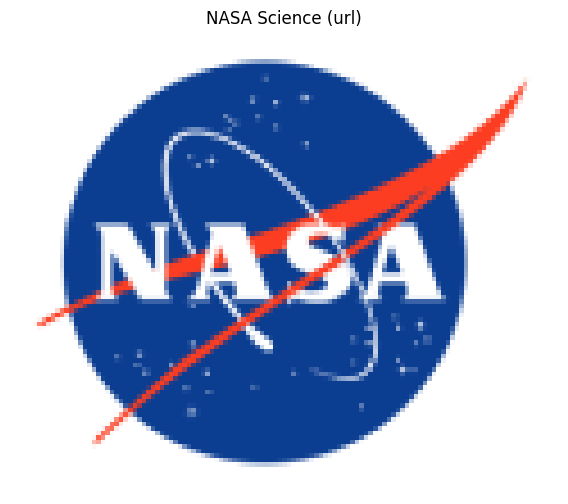

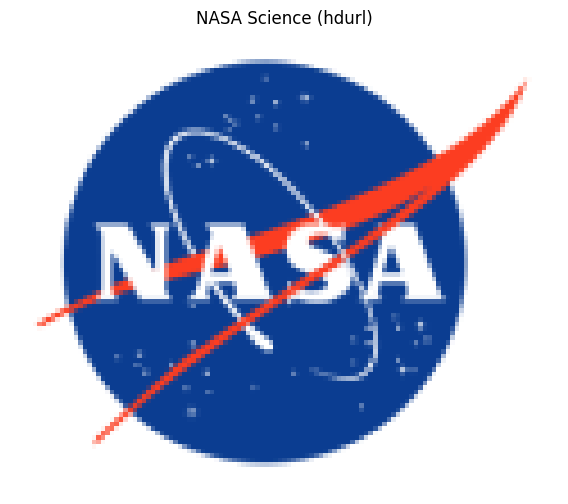

In [11]:
import urllib.request
from pprint import pprint
import matplotlib.pyplot as plt
from skimage import io

url = "https://api.nasa.gov/planetary/apod?api_key=DEMO_KEY"
try:
    with urllib.request.urlopen(url, timeout=15) as page:
        page_content = page.read()
    page_content.decode('utf-8')            # bytes -> string
    json_page = json.loads(page_content)    # process the data with JSON

    for x in json_page:                     # print the keys
        print(x)
    print()
    for x in json_page:                     # print keys and values
        print(x + " -->", json_page[x])
    print()
    pprint(json_page)

    if json_page.get('media_type') == 'image':
        for key in ('url', 'hdurl'):
            if key in json_page:
                plt.figure(figsize=(8, 6))
                plt.imshow(io.imread(json_page[key]))
                plt.axis('off'); plt.title(f"{json_page['title']} ({key})")
                plt.show()
    else:
        print("Today's APOD is a", json_page.get('media_type'), "- link:", json_page.get('url'))
except Exception as e:
    print('NASA API not available right now (DEMO_KEY is rate-limited):', e)

## 9. Web scraping with JSON – example 2: Citi Bike NYC
The old `feeds.citibikenyc.com/stations/stations.json` feed from the slide is retired, so the code falls back to Citi Bike's current GBFS feed.

In [12]:
import requests

try:
    json_response = requests.get("https://feeds.citibikenyc.com/stations/stations.json", timeout=10)
    json_response.raise_for_status()
    bike_dict = json.loads(json_response.text)
    print(type(json_response.text)); print(type(bike_dict))
    for key in bike_dict:
        print(key)
    print(json.dumps(bike_dict['stationBeanList'][0], indent=3))
except Exception as e:
    print('Old feed unavailable (', type(e).__name__, ') – using the current GBFS feed')
    json_response = requests.get("https://gbfs.citibikenyc.com/gbfs/en/station_information.json", timeout=10)
    print(type(json_response.text))
    bike_dict = json.loads(json_response.text)
    print(type(bike_dict))
    for key in bike_dict:
        print(key)
    stations = bike_dict['data']['stations']
    print(f"\n{len(stations)} stations. First one:")
    print(json.dumps(stations[0], indent=3))

Old feed unavailable ( ConnectionError ) – using the current GBFS feed
<class 'str'>
<class 'dict'>
data
last_updated
ttl
version

2520 stations. First one:
{
   "station_id": "66dc292c-0aca-11e7-82f6-3863bb44ef7c",
   "name": "Broadway & W 41 St",
   "short_name": "6560.01",
   "lon": -73.98658032,
   "lat": 40.75513557,
   "region_id": "71",
   "capacity": 55,
   "rental_uris": {
      "android": "https://bkn.lft.to/lastmile_qr_scan",
      "ios": "https://bkn.lft.to/lastmile_qr_scan"
   },
   "rental_methods": [
      "KEY",
      "CREDITCARD"
   ],
   "has_kiosk": true,
   "station_type": "classic",
   "external_id": "66dc292c-0aca-11e7-82f6-3863bb44ef7c",
   "electric_bike_surcharge_waiver": false,
   "eightd_station_services": [],
   "eightd_has_key_dispenser": false
}


# Part B – Exercise
## 10. Create `students.json` on Drive
Each student is a JSON object with: first name, last name, Braude email, this semester's courses (a list), an interesting link and a favorite show.
The data comes from our Lab 1 file `students.txt`. If `students.json` already exists it is kept, so earlier updates are not lost.

In [13]:
import os, glob

BASE = '/content/drive/MyDrive'
JSON_FILE = os.path.join(BASE, 'students.json')

def from_txt(path):
    # Lab 1 line format: first,last,email,course1; course2; ...,link,favorite show
    students = {}
    with open(path, encoding='utf-8') as f:
        for line in f:
            parts = [p.strip() for p in line.strip().split(',')]
            if len(parts) < 6 or not parts[2]:
                continue
            first, last, email, courses, link = parts[:5]
            show = ','.join(parts[5:]).strip()
            s = students.setdefault(email.lower(), {
                'first_name': first, 'last_name': last, 'email': email,
                'courses': [], 'link': link, 'favorite_show': ''})
            s['courses'] = [c.strip() for c in courses.split(';') if c.strip()]
            if show:
                s['favorite_show'] = show        # Lab 1 appended lines, the latest one wins
    return list(students.values())

DEFAULT = [
    {'first_name': 'Ali', 'last_name': 'Armosh', 'email': 'ali.armosh@e.braude.ac.il',
     'courses': ['Data Mining and Learning Systems', 'Advanced Internet Technologies (WEB)',
                 'Automata and Computability', 'Physics for Software Engineering',
                 'Introduction to Cloud Computing', 'Introduction to Artificial Intelligence'],
     'link': 'https://colab.research.google.com', 'favorite_show': 'The Office'},
    {'first_name': 'Omri', 'last_name': 'Tafesh', 'email': 'omri.tafesh@e.braude.ac.il',
     'courses': ['Algorithms', 'Advanced Internet Technologies (WEB)', 'Introduction to Cloud Computing',
                 'Physics for Software Engineering', 'Sport 1'],
     'link': 'https://www.braude.ac.il', 'favorite_show': 'Breaking Bad'}]

if os.path.exists(JSON_FILE):
    print('students.json already exists on Drive – keeping it.')
else:
    txt = os.path.join(BASE, 'students.txt')
    data = from_txt(txt) if os.path.exists(txt) else DEFAULT
    print('Built from Lab 1 students.txt' if os.path.exists(txt) else 'students.txt not found – using built-in data')
    with open(JSON_FILE, 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=4, ensure_ascii=False)
    print('Created', JSON_FILE)

with open(JSON_FILE, encoding='utf-8') as f:
    print(json.dumps(json.load(f), indent=4, ensure_ascii=False))

students.json already exists on Drive – keeping it.
[
    {
        "first_name": "Ali",
        "last_name": "Armosh",
        "email": "ali.armosh@e.braude.ac.il",
        "courses": [
            "Data Mining and Learning Systems",
            "Advanced Internet Technologies (WEB)",
            "Automata and Computability",
            "Physics for Software Engineering",
            "Introduction to Cloud Computing",
            "Introduction to Artificial Intelligence"
        ],
        "link": "https://colab.research.google.com",
        "favorite_show": "Lupin"
    },
    {
        "first_name": "Omri",
        "last_name": "Tafesh",
        "email": "omri.tafesh@e.braude.ac.il",
        "courses": [
            "Algorithms",
            "Advanced Internet Technologies (WEB)",
            "Introduction to Cloud Computing",
            "Physics for Software Engineering",
            "Sport 1"
        ],
        "link": "https://www.braude.ac.il",
        "favorite_show": "Breakin

## 11. The form – choose a student, see their details, update their favorite show

In [14]:
import ipywidgets as widgets
from IPython.display import display, HTML

def load_students():
    with open(JSON_FILE, encoding='utf-8') as f:
        return json.load(f)

def save_students(data):
    with open(JSON_FILE, 'w', encoding='utf-8') as f:
        json.dump(data, f, indent=4, ensure_ascii=False)

students = load_students()
full_name = lambda s: f"{s['first_name']} {s['last_name']}"

display(HTML('''<style>
.lab2 {background: linear-gradient(135deg,#0f2027,#203a43,#2c5364); padding:22px; border-radius:16px; box-shadow:0 6px 20px rgba(0,0,0,.35);}
.lab2 .widget-label {color:#e0f7fa !important; font-weight:600;}
.lab2 input, .lab2 textarea, .lab2 select {border-radius:8px !important;}
</style>'''))

W = {'description_width': '120px'}
L = widgets.Layout(width='500px')
title    = widgets.HTML("<h2 style='color:#4dd0e1;margin:0 0 12px'>🎓 Shablool – Student Details (JSON)</h2>")
dd       = widgets.Dropdown(options=[full_name(s) for s in students], description='Student:', style=W, layout=L)
first    = widgets.Text(description='First name:',  disabled=True, style=W, layout=L)
last     = widgets.Text(description='Last name:',   disabled=True, style=W, layout=L)
email    = widgets.Text(description='Braude mail:', disabled=True, style=W, layout=L)
courses  = widgets.Textarea(description='Courses:', disabled=True, style=W, layout=widgets.Layout(width='500px', height='135px'))
link_txt = widgets.Text(description='Link:',        disabled=True, style=W, layout=L)
link_btn = widgets.HTML()
show     = widgets.Text(description='Favorite show:', disabled=True, style=W, layout=L)
new_show = widgets.Text(description='New show:', placeholder='Type the new favorite show...', style=W, layout=L)
btn      = widgets.Button(description='Update', button_style='info', icon='save')
out      = widgets.Output()

def fill(name):
    s = next(x for x in students if full_name(x) == name)
    first.value, last.value, email.value = s['first_name'], s['last_name'], s['email']
    courses.value  = '\n'.join(s['courses'])
    link_txt.value = s['link']
    link_btn.value = f"<a href='{s['link']}' target='_blank' style='color:#80deea;margin-left:124px'>open link ↗</a>"
    show.value     = s.get('favorite_show', '')

def on_select(change):
    fill(change['new'])
    new_show.value = ''
    out.clear_output()
dd.observe(on_select, names='value')

def on_update(b):
    out.clear_output()
    with out:
        val = new_show.value.strip()
        if not val:
            print('⚠️ Type a show first.')
            return
        data = load_students()                 # re-read the file
        for s in data:
            if full_name(s) == dd.value:
                s['favorite_show'] = val       # update only this student's record
        save_students(data)                    # write back to students.json on Drive
        students[:] = data
        fill(dd.value)
        new_show.value = ''
        print(f'✅ {dd.value} updated in students.json')
btn.on_click(on_update)

fill(dd.value)
box = widgets.VBox([title, dd, first, last, email, courses, link_txt, link_btn, show, new_show, btn, out])
box.add_class('lab2')
display(box)

## 12. Check – print `students.json` after updating
Run this cell after pressing Update to see the change saved in the file.

In [15]:
with open(JSON_FILE, encoding='utf-8') as f:
    print(f.read())

[
    {
        "first_name": "Ali",
        "last_name": "Armosh",
        "email": "ali.armosh@e.braude.ac.il",
        "courses": [
            "Data Mining and Learning Systems",
            "Advanced Internet Technologies (WEB)",
            "Automata and Computability",
            "Physics for Software Engineering",
            "Introduction to Cloud Computing",
            "Introduction to Artificial Intelligence"
        ],
        "link": "https://colab.research.google.com",
        "favorite_show": "Lupin"
    },
    {
        "first_name": "Omri",
        "last_name": "Tafesh",
        "email": "omri.tafesh@e.braude.ac.il",
        "courses": [
            "Algorithms",
            "Advanced Internet Technologies (WEB)",
            "Introduction to Cloud Computing",
            "Physics for Software Engineering",
            "Sport 1"
        ],
        "link": "https://www.braude.ac.il",
        "favorite_show": "Breaking Bad"
    }
]


## 13. Backup to Git
File → Save a copy in GitHub → choose the team repository.